# 00 — Environment & Data Check
**KhabarNazar — Image Analysis Module**

Checks that the GPU works and that all three datasets are downloaded and in the right place before training.

| Stage | Dataset | Purpose |
|---|---|---|
| 1 | AI vs Real (tristanzhang32) | Main training — 30k real + 30k AI-generated full-resolution images |
| 2 | Tiny-GenImage | Second training stage + unseen-generator test (8 generators) |
| 3 | Misinfo-dataset | Unseen test set — fake-news / sensitive topics, newest generators |

## 1. Environment

In [1]:
import sys, io, random
from pathlib import Path

import torch
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
IMG_EXT = {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".tif", ".tiff"}

print("Python :", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU    :", torch.cuda.get_device_name(0))
print("Data folder:", DATA, "| exists:", DATA.exists())

Python : 3.12.4
PyTorch: 2.11.0+cu128
CUDA available: True
GPU    : NVIDIA RTX A4000
Data folder: E:\FYP\KhabarNazar\image_module\data | exists: True


In [2]:
def folder_table(root):
    """Every folder under root that directly contains images, with its image count."""
    root = Path(root)
    rows = []
    for d in sorted([root] + [p for p in root.rglob("*") if p.is_dir()]):
        n = sum(1 for f in d.iterdir() if f.is_file() and f.suffix.lower() in IMG_EXT)
        if n:
            rows.append({"folder": str(d.relative_to(root)), "images": n})
    return pd.DataFrame(rows, columns=["folder", "images"])

def show_grid(images, titles, ncols=6, size=2.6, suptitle=None):
    nrows = -(-len(images) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, img, title in zip(axes.flat, images, titles):
        img = img if isinstance(img, Image.Image) else Image.open(img)
        ax.imshow(img.convert("RGB"))
        ax.set_title(title, fontsize=8)
    if suptitle:
        fig.suptitle(suptitle)
    plt.tight_layout()
    plt.show()

def samples_from(root, table, n=12, seed=0):
    """Pick n random images spread across the folders in table."""
    rng = random.Random(seed)
    imgs, titles = [], []
    folders = list(table["folder"])
    for i in range(n):
        folder = folders[i % len(folders)]
        files = [p for p in (Path(root) / folder).iterdir() if p.suffix.lower() in IMG_EXT]
        p = rng.choice(files)
        img = Image.open(p)
        imgs.append(img); titles.append(f"{folder[-24:]}\n{img.size[0]}x{img.size[1]}")
    return imgs, titles

## 2. AI vs Real (tristanzhang32)
Expected: 60,000 images in total (30k real, 30k AI-generated), with about 20% in a test split.

In [3]:
AIVR = DATA / "ai_vs_real"
aivr_df = folder_table(AIVR)
display(aivr_df)
print("Total images:", aivr_df["images"].sum())

,folder,images
0,test\fake,6000
1,test\real,6000
2,train\fake,24000
3,train\real,24000


Total images: 60000


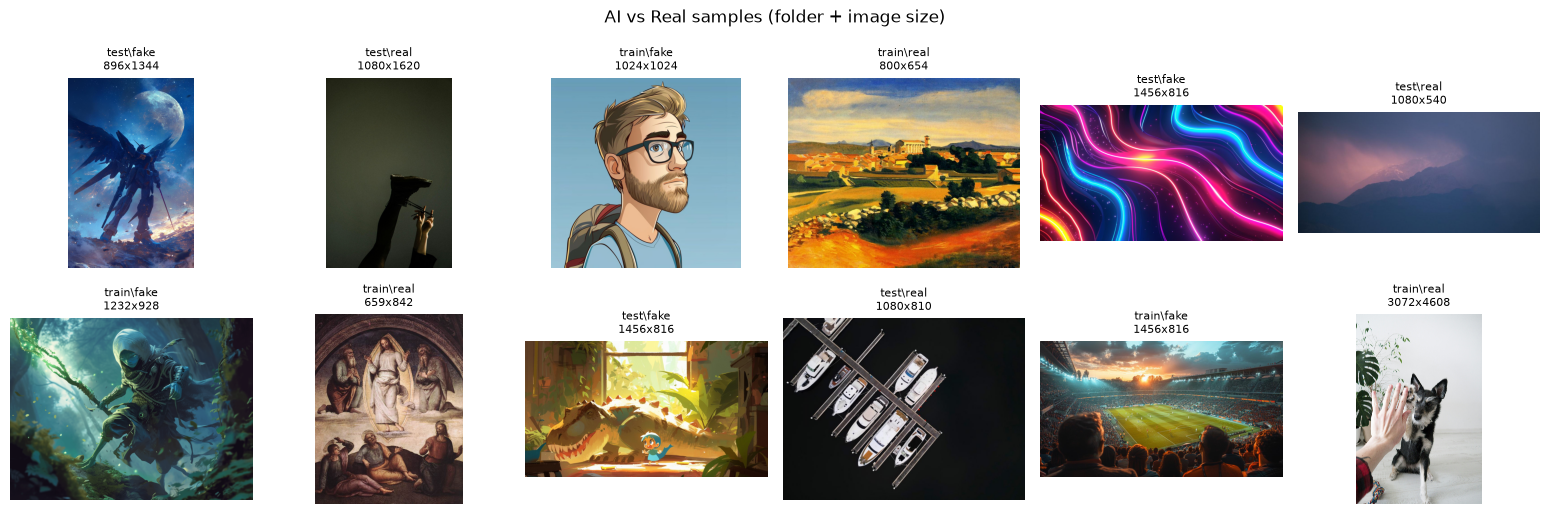

In [4]:
imgs, titles = samples_from(AIVR, aivr_df, n=12)
show_grid(imgs, titles, ncols=6, suptitle="AI vs Real samples (folder + image size)")

## 3. Tiny-GenImage
Stored as Parquet files (image + `label` + `generator` columns).
Expected: 28,000 train and 7,000 validation images.

In [5]:
import pyarrow.parquet as pq

TINY = DATA / "tiny_genimage"
LABEL_NAMES = ["real", "fake"]
GEN_NAMES = ["Real", "ADM", "BigGAN", "GLIDE", "Midjourney", "SD14", "SD15", "VQDM", "Wukong"]

parquet_files = sorted(TINY.rglob("*.parquet"))
train_files = [f for f in parquet_files if "train" in f.name]
val_files = [f for f in parquet_files if "valid" in f.name]
print(f"{len(train_files)} train files, {len(val_files)} validation files")
print("Columns:", pq.read_schema(parquet_files[0]).names)

def read_meta(files):
    return pd.concat([pq.read_table(f, columns=["label", "generator"]).to_pandas() for f in files],
                     ignore_index=True)

meta = {"train": read_meta(train_files), "validation": read_meta(val_files)}
for split, df in meta.items():
    df["label_name"] = df["label"].map(dict(enumerate(LABEL_NAMES)))
    df["generator_name"] = df["generator"].map(dict(enumerate(GEN_NAMES)))
    print(f"\n{split}: {len(df)} images")
    display(pd.crosstab(df["generator_name"], df["label_name"], margins=True))

14 train files, 4 validation files
Columns: ['image', 'label', 'generator']

train: 28000 images


label_name,fake,real,All
generator_name,,,
ADM,2000,0,2000
BigGAN,2000,0,2000
GLIDE,2000,0,2000
Midjourney,2000,0,2000
Real,0,14000,14000
SD15,2000,0,2000
VQDM,2000,0,2000
Wukong,2000,0,2000
All,14000,14000,28000



validation: 7000 images


label_name,fake,real,All
generator_name,,,
ADM,500,0,500
BigGAN,500,0,500
GLIDE,500,0,500
Midjourney,500,0,500
Real,0,3500,3500
SD15,500,0,500
VQDM,500,0,500
Wukong,500,0,500
All,3500,3500,7000


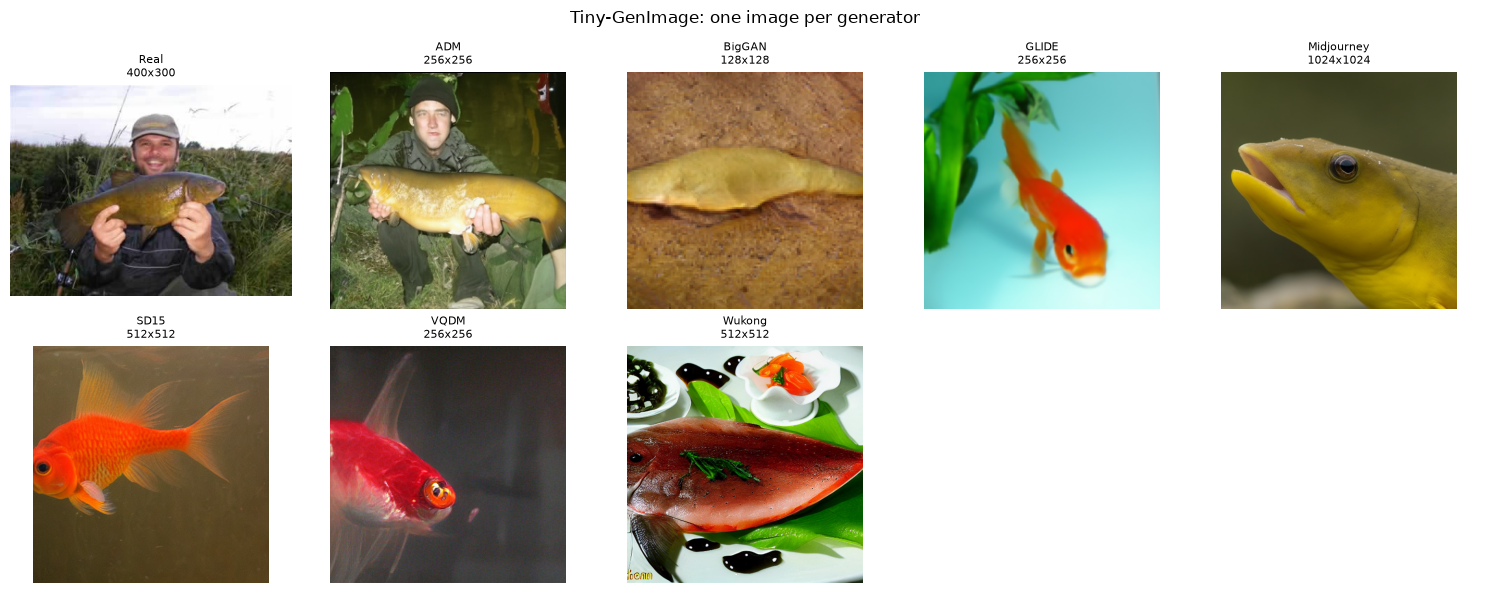

In [6]:
# One sample image per generator
samples = {}
for f in train_files:
    for batch in pq.ParquetFile(f).iter_batches(batch_size=64, columns=["image", "generator"]):
        for row in batch.to_pylist():
            name = GEN_NAMES[row["generator"]]
            if name not in samples:
                samples[name] = Image.open(io.BytesIO(row["image"]["bytes"]))
        if len(samples) == len(GEN_NAMES):
            break
    if len(samples) == len(GEN_NAMES):
        break

names = [n for n in GEN_NAMES if n in samples]
show_grid([samples[n] for n in names], [f"{n}\n{samples[n].size[0]}x{samples[n].size[1]}" for n in names],
          ncols=5, size=3, suptitle="Tiny-GenImage: one image per generator")

## 4. Misinfo-dataset
Unseen evaluation set (fake-news / sensitive topics). Never used for training.

In [7]:
MISINFO = DATA / "misinfo"
mis_df = folder_table(MISINFO)
display(mis_df)
print("Total images:", mis_df["images"].sum())

,folder,images
0,FLUX1-dev\val\ai,1000
1,FLUX1-dev\val\nature,1000
2,imagen3\val\ai,1000
3,imagen3\val\nature,1000
4,PixArt-XL-2-1024-MS\val\ai,1000
5,PixArt-XL-2-1024-MS\val\nature,1000
6,SDXL1\val\ai,1000
7,SDXL1\val\nature,1000


Total images: 8000


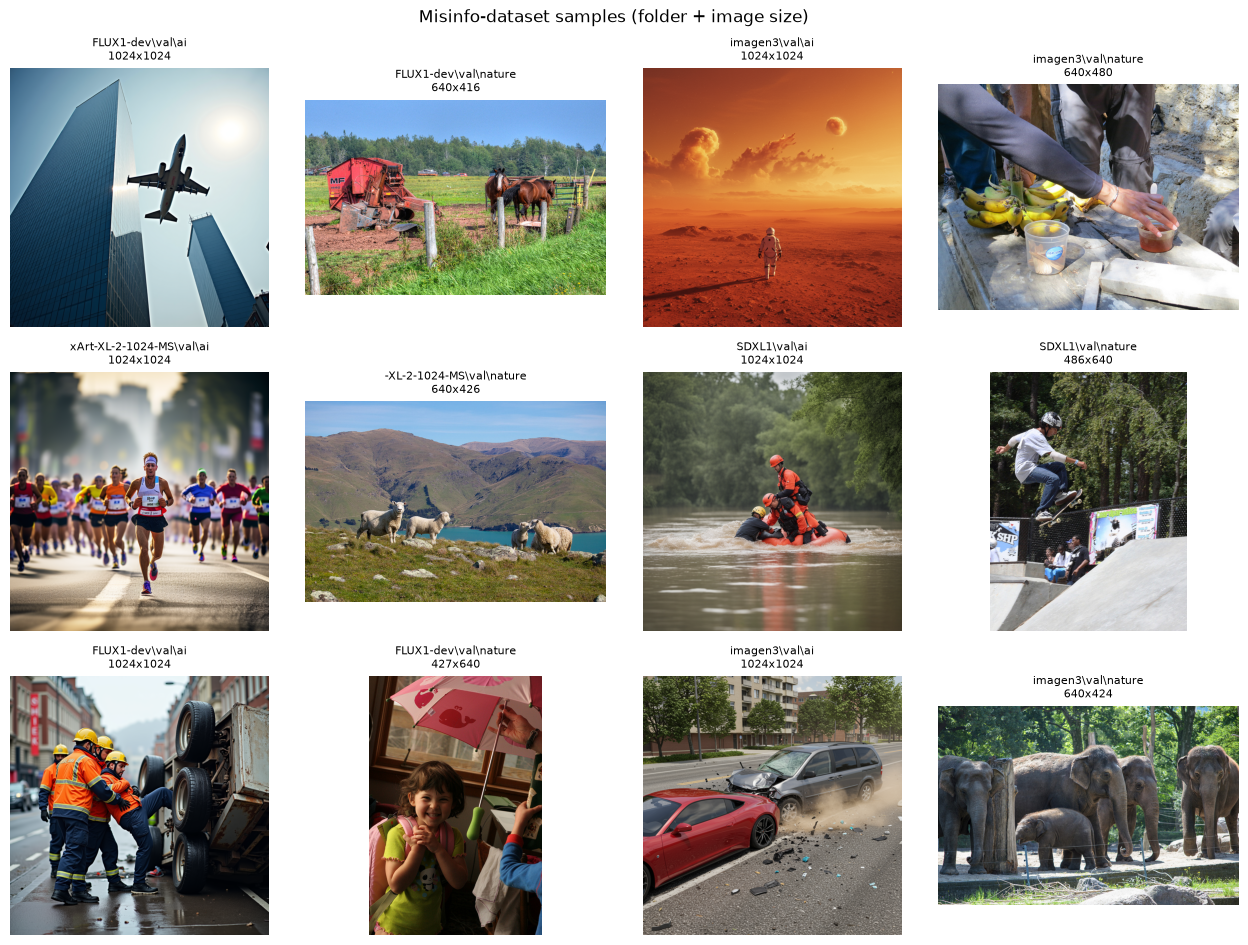

In [8]:
imgs, titles = samples_from(MISINFO, mis_df, n=12, seed=1)
show_grid(imgs, titles, ncols=4, size=3.2, suptitle="Misinfo-dataset samples (folder + image size)")

## 5. Summary
If every count looks right and the sample images display, the environment and data are ready.
Next: **01_train_ai_vs_real.ipynb**.